# 2.1_phyloseq-dada2

Decided to use the dada2 taxonomic assignment tool going forward, as it classified 2x more reads as bacteria. 

## 11.2.26 | create phyloseq object

To see how I cleaned and tided the sample metadata, refer to notebook `1.9_phyloseq-decipher.ipynb`

In [13]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
})

options(repr.plot.width=15, repr.plot.height=8)

In [2]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.rds")

# Read taxonomy table
taxaTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/taxa_species.rds")

# Read tidied metadata
metadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [3]:
# Check that row names are identical
head(asvTable)
head(metadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both05_Warm03_O33_gut,2024,BW,Both,5,Warm,3,O33,2,gut,53.0,⋯,<15uL,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.10,4.10,
2024_Both06_Hyp06_O72_gut,2024,BH,Both,6,Hyp,6,O72,2,gut,53.8,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.88,2.82,
2024_Cont02_Warm02_W15_gut,2024,CW,Cont,2,Warm,2,W15,2,gut,29.2,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.64,3.77,
2024_Both03_Warm01_O6_gut,2024,BW,Both,3,Warm,1,O6,2,gut,77.8,⋯,<15uL,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,10.00,2.50,
2024_Both03_Warm04_O41_gut,2024,BW,Both,3,Warm,4,O41,2,gut,86.9,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,9.86,2.54,
2024_Both04_Warm02_O19_gut,2024,BW,Both,4,Warm,2,O19,2,gut,38.7,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,7.52,3.32,


In [4]:
# Rearrange metadata sample order to match ASV table sample order
metadata <- metadata[match(rownames(asvTable), rownames(metadata)), ]
head(asvTable)
head(metadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both01_Both01_O1_gill,2024,BB,Both,1,Both,1,O1,2,gill,18.100,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.66,3.75,
2024_Both01_Both01_O1_gut,2024,BB,Both,1,Both,1,O1,2,gut,43.000,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.24,3.03,
2024_Both01_Null_O03_gill,2024,BNA,Both,1,NA,NA,O03,1,gill,0.980,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,4.98,5.02,
2024_Both01_Null_O03_gut,2024,BNA,Both,1,NA,NA,O03,1,gut,0.886,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,5.80,4.31,Diluted final sample 1:3
2024_Both01_Warm05_O50_gill,2024,BW,Both,1,Warm,5,O50,2,gill,75.200,⋯,,BFi-13,2026-07-06,1,7/6/26,NA,NA,10.07,2.48,Diluted final sample 1:3
2024_Both01_Warm05_O50_gut,2024,BW,Both,1,Warm,5,O50,2,gut,46.900,⋯,,BFi-15,2026-07-03,2,7/3/26,NA,NA,7.40,3.38,Diluted final sample 1:3


In [5]:
# Create phyloseq object
ps <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(metadata),
                     tax_table(taxaTable))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]

In [6]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(ps))
names(dna) <- taxa_names(ps)

# Create reference sequence component of phyloseq object to store the raw ASVs
ps <- merge_phyloseq(ps, dna)

# Rename ASVs numerically
taxa_names(ps) <- paste0("ASV", seq(ntaxa(ps)))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

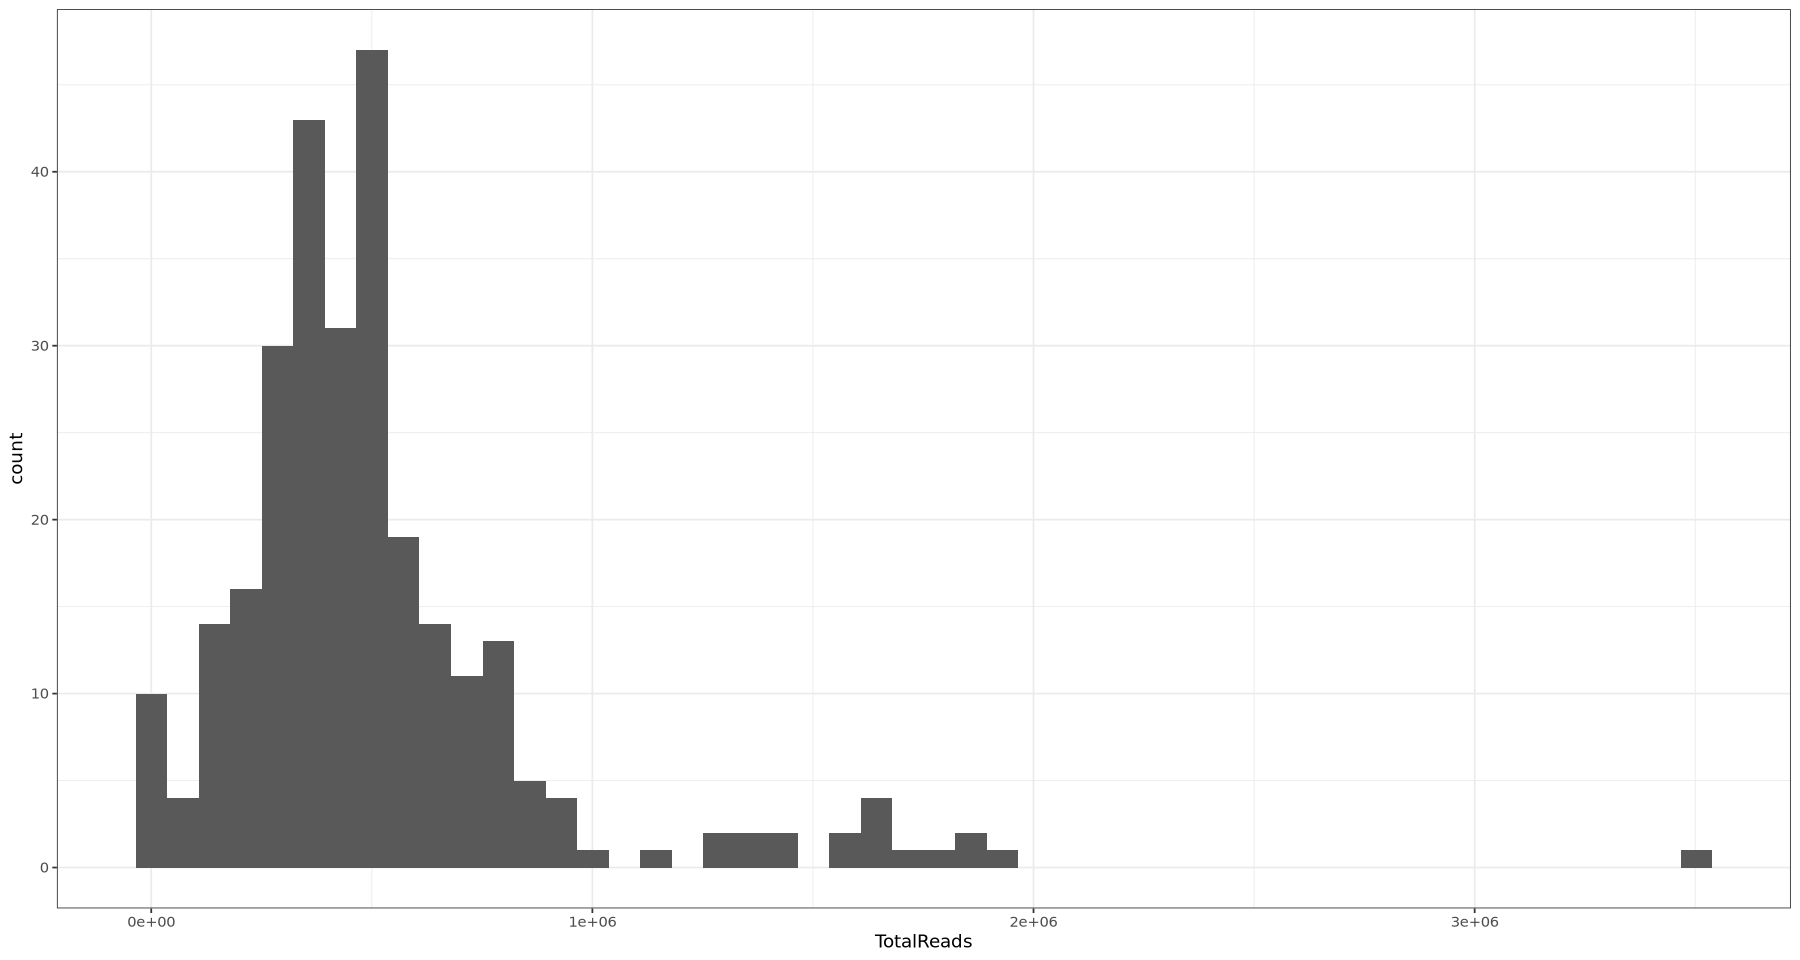

In [15]:
# Check read count of all samples
readcount = data.table(as(sample_data(ps), "data.frame"),
                 TotalReads = sample_sums(ps), 
                 keep.rownames = TRUE)
ggplot(readcount, aes(TotalReads)) + 
    geom_histogram(bins = 50) + 
    theme_bw()

In [55]:
# Check kingdom level classification of all samples
table(tax_table(ps)[, "Kingdom"], useNA = "ifany")


  Archaea  Bacteria Eukaryota      <NA> 
     3464    139132      2207       572 

Much higher levels of classification compared to decipher taxonomic assignment tool (Bacteria = 66,795 and NA = 77,588).

In [7]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2.rds")

## 11.3.26 | initial filtering and transformation

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(microbiome)
})

options(repr.plot.width=15, repr.plot.height=8)

In [49]:
# Read in raw phyloseq object
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2.rds")

### Unclassified ASVs

Kingdom  Phylum   Class   Order  Family   Genus Species 
   0.39   12.13   16.25   35.57   51.14   77.91   99.54

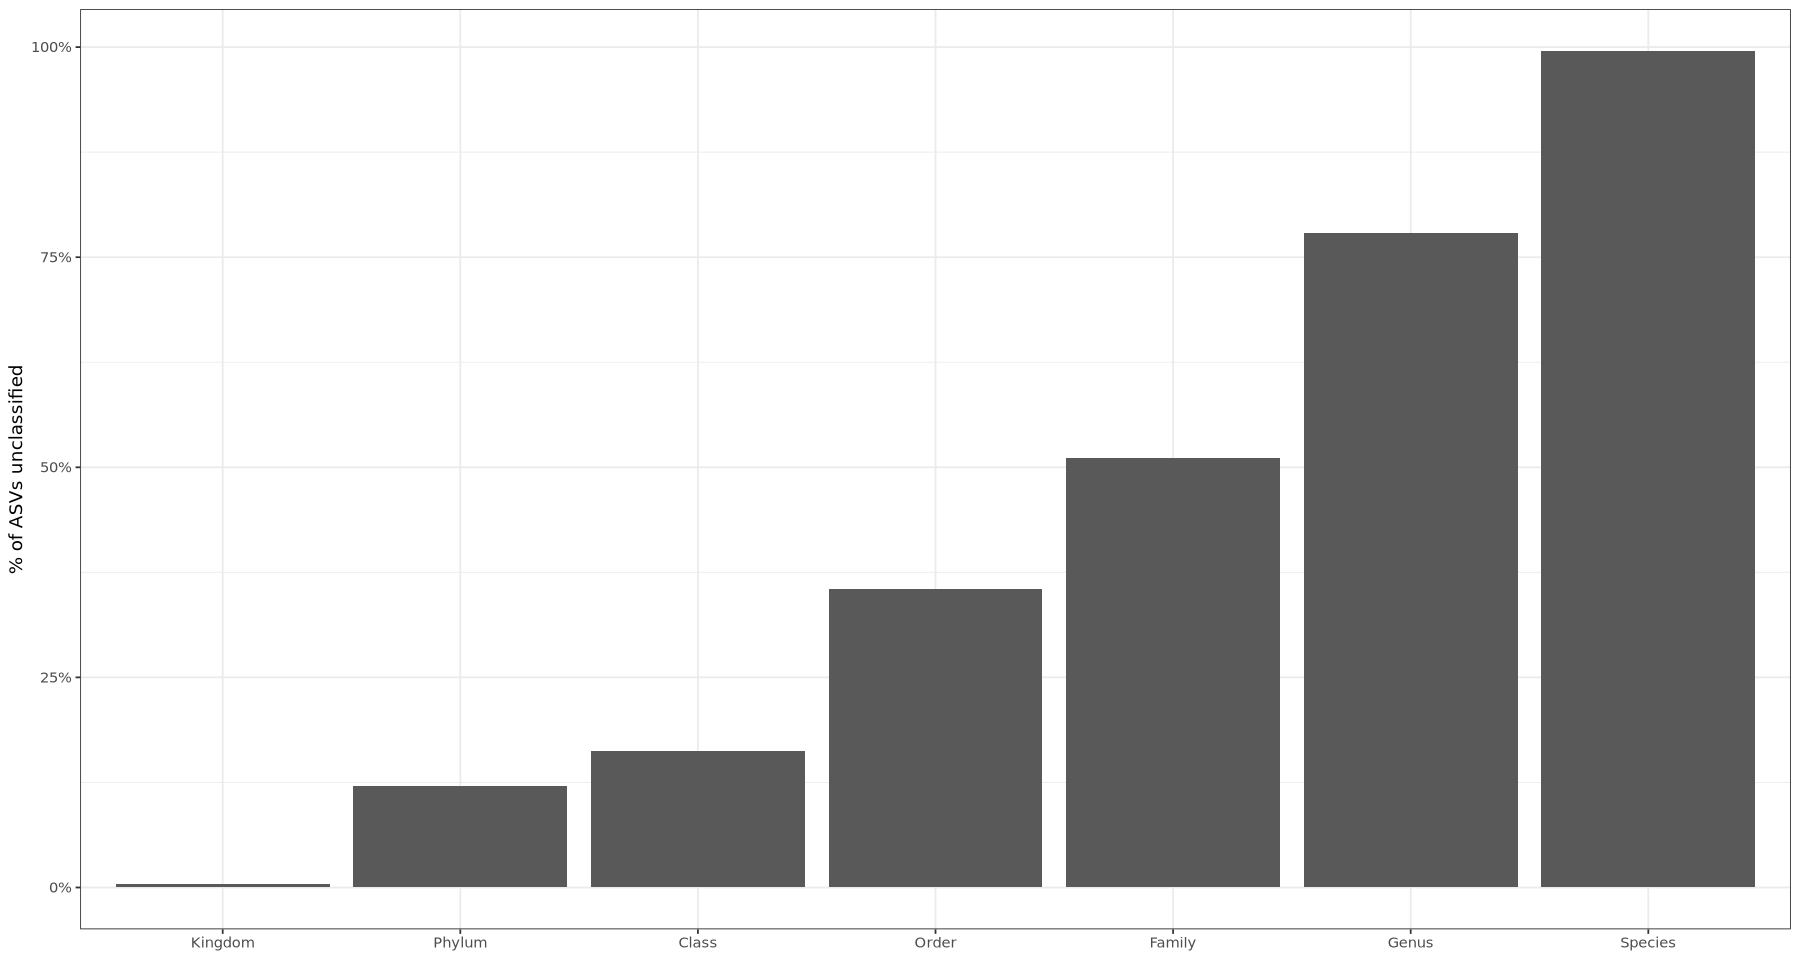

In [3]:
# Create data frame from phyloseq tax_table matrix
tax_df <- as.data.frame(tax_table(ps))

# Proportion of ASVs unclassified (NA) at each rank
tax_completeness <- sapply(tax_df, function(x) round(mean(is.na(x) | x == "") * 100, 2))
tax_completeness

# Plot unclassified ASVs
data.frame(Rank = factor(names(tax_completeness), levels = names(tax_completeness)), PercentUnclassified = tax_completeness) %>%
ggplot(aes(x = Rank, y = PercentUnclassified)) +
    geom_col() +
    scale_y_continuous(labels = scales::label_percent(scale = 1)) +
    labs(y = "% of ASVs unclassified", x = NULL) +
    theme_bw()

Looks okay - all ASVs were assigned a kingdom and ~88% were assigned a phylum. Also seems normal that only about a quarter of ASVs were classified to the genus level. Optional to remove ASVs that are unclassified at the phylum/class/order level to reduce noise in downstream analyses.

In [5]:
# Remove unclassified ASVs at the phylum level
n_before <- ntaxa(ps)
ps_phylum <- subset_taxa(ps, !is.na(Phylum))
n_after_p <- ntaxa(ps_phylum)
sprintf(
  "Removed %d ASVs unclassified at Phylum level (%d -> %d)",
  n_before - n_after_p, n_before, n_after_p
)

# Remove unclassified ASVs at the class level
ps_class <- subset_taxa(ps, !is.na(Class))
n_after_c <- ntaxa(ps_class)
sprintf(
  "Removed %d ASVs unclassified at Class level (%d -> %d)",
  n_before - n_after_c, n_before, n_after_c
)

# Remove unclassified ASVs at the order level
ps_order <- subset_taxa(ps, !is.na(Order))
n_after_o <- ntaxa(ps_order)
sprintf(
  "Removed %d ASVs unclassified at Order level (%d -> %d)",
  n_before - n_after_o, n_before, n_after_o
)

[1] "Removed 17638 ASVs unclassified at Phylum level (145375 -> 127737)"

[1] "Removed 23617 ASVs unclassified at Class level (145375 -> 121758)"

[1] "Removed 51712 ASVs unclassified at Order level (145375 -> 93663)"

In [8]:
# Total number of bacteria ASVs
n_bacteria <- sum(tax_table(ps)[, "Kingdom"] == "Bacteria", na.rm = TRUE)
p_bacteria <- (n_bacteria / ntaxa(ps)) * 100
sprintf(
  "%d ASVs are classified as bacteria, or %.1f%% of all ASVs",
  n_bacteria, p_bacteria
)

# Bacteria ASV lost due to removal of unclassified Phylum 
n_bacteria_p <- sum(tax_table(ps_phylum)[, "Kingdom"] == "Bacteria", na.rm = TRUE)
sprintf(
  "When unclassified Phylum are removed, %d ASVs are classified as bacteria (%d bacteria ASV are lost)",
  n_bacteria_p, n_bacteria - n_bacteria_p
)

# Bacteria ASV lost due to removal of unclassified Class
n_bacteria_c <- sum(tax_table(ps_class)[, "Kingdom"] == "Bacteria", na.rm = TRUE)
sprintf(
  "When unclassified Class are removed, %d ASVs are classified as bacteria (%d bacteria ASV are lost)",
  n_bacteria_c, n_bacteria - n_bacteria_c
)

# Bacteria ASV lost due to removal of unclassified Order
n_bacteria_o <- sum(tax_table(ps_order)[, "Kingdom"] == "Bacteria", na.rm = TRUE)
sprintf(
  "When unclassified Order are removed, %d ASVs are classified as bacteria (%d bacteria ASV are lost)",
  n_bacteria_o, n_bacteria - n_bacteria_o
)

[1] "139132 ASVs are classified as bacteria, or 95.7% of all ASVs"

[1] "When unclassified Phylum are removed, 124316 ASVs are classified as bacteria (14816 bacteria ASV are lost)"

[1] "When unclassified Class are removed, 118340 ASVs are classified as bacteria (20792 bacteria ASV are lost)"

[1] "When unclassified Order are removed, 90318 ASVs are classified as bacteria (48814 bacteria ASV are lost)"

Bacteria are lost when filtering out ASVs unclassified at the phylum/class/order level, especially between class and order. Based on this, I will be slightly more conservative and remove ASVs that are unclassified at the class level. However the biological relevance of and/or confidence in ASVs that can't be classified to at least the order level is worth thinking more about.

In [16]:
# Use class level filtering moving forward
ps <- ps_class

### Chloroplast and mitochondria

In [17]:
# Pull the taxonomy as a data frame
tax_df2 <- as.data.frame(tax_table(ps))

# Identify chloroplast and mitochondrial ASVs by name
chloro_asvs <- tax_df2 %>% filter(Order=="Chloroplast")%>% rownames()
mito_asvs   <- tax_df2 %>% filter(Family=="Mitochondria")%>% rownames()

length(chloro_asvs)
length(mito_asvs)

# What proportion of total reads do they represent?
sum(otu_table(ps)[, chloro_asvs]) / sum(otu_table(ps))
sum(otu_table(ps)[, mito_asvs])   / sum(otu_table(ps))

# Remove only mitochondria
n_before <- ntaxa(ps)
ps <- prune_taxa(!taxa_names(ps) %in% mito_asvs, ps)
n_after <- ntaxa(ps)

sprintf(
  "Removed %d mitochondrial ASVs (%d -> %d)",
  n_before - n_after, n_before, n_after
)

[1] 2785

[1] 1362

[1] 0.1128566

[1] 0.008540647

[1] "Removed 1362 mitochondrial ASVs (121758 -> 120396)"

Only removed mitochondria as chloroplast may play a role in differentiating tissue types since oysters feed on algae. Could be useful to remove later depending on the analysis.

### Negative control contaminants

In [30]:
# Identify the negative control sample
blank_id <- "negative_control_NA"

# Extract the blank's read counts as a named numeric vector
blank_counts <- as.numeric(otu_table(ps)[blank_id, ])
names(blank_counts) <- taxa_names(ps)

# How many ASVs have non-zero counts in the blank?
sum(blank_counts > 0)

# Inspect the most abundant ASVs in the blank
sort(blank_counts[blank_counts > 0], decreasing = TRUE) %>% head(20)

# Look at the taxonomy of those ASVs
top_blank_asvs <- names(sort(blank_counts, decreasing = TRUE))[1:20]
tax_table(ps)[top_blank_asvs, ]

[1] 134

ASV27   ASV15  ASV137  ASV241    ASV6   ASV67  ASV115  ASV487  ASV750 ASV1448 
  55309   10197   10127    8513    7893    7808    7217    5775    5600    5348 
 ASV453 ASV1655 ASV1706 ASV1493 ASV1472 ASV1016  ASV534  ASV398 ASV3103  ASV154 
   5299    4478    4473    4365    3448    2382    1971    1944    1884    1558

,Kingdom,Phylum,Class,Order,Family,Genus,Species
ASV27,Bacteria,Pseudomonadota,Alphaproteobacteria,Hyphomicrobiales,Xanthobacteraceae,Bradyrhizobium,NA
ASV15,Bacteria,Pseudomonadota,Alphaproteobacteria,NA,NA,NA,NA
ASV137,Archaea,Halobacteriota,Halobacteria,Halobacterales,Haloferacaceae,Haloparvum,NA
ASV241,Archaea,Halobacteriota,Halobacteria,Halobacterales,Haloferacaceae,Halorubrum,NA
ASV6,Bacteria,Pseudomonadota,Alphaproteobacteria,Rickettsiales,NA,NA,NA
ASV67,Bacteria,Actinomycetota,Actinobacteria,Propionibacteriales,Propionibacteriaceae,Cutibacterium,NA
ASV115,Bacteria,Bacillota,Bacilli,Staphylococcales,Staphylococcaceae,Staphylococcus,NA
ASV487,Bacteria,Pseudomonadota,Alphaproteobacteria,Hyphomicrobiales,Beijerinckiaceae,Methylorubrum,NA
ASV750,Bacteria,Planctomycetota,Planctomycetes,Pirellulales,Pirellulaceae,NA,NA
ASV1448,Archaea,Halobacteriota,Halobacteria,Halobacterales,Haloferacaceae,Haloplanus,NA


The negative control sample has 134 ASVs associated with it, and some of the ASVs have a raw abundance as high as ~55k but only 3 ASVs appear > 10,000 times. Some of these are classified as Archaea. 

In [31]:
# Set number of ASV occurances to count as a contaminant
contaminant_threshold <- 1000
contaminants <- names(blank_counts)[blank_counts > contaminant_threshold]
length(contaminants)
contaminants

# Remove the flagged ASVs from the entire dataset
n_before <- ntaxa(ps)
ps <- subset_taxa(ps, !taxa_names(ps) %in% contaminants)
n_after <- ntaxa(ps)

sprintf(
  "Removed %d contaminant ASVs based on blank (%d -> %d)",
  n_before - n_after, n_before, n_after
)

[1] 22

[1] "ASV6"    "ASV15"   "ASV27"   "ASV67"   "ASV115"  "ASV137"  "ASV154" 
 [8] "ASV241"  "ASV398"  "ASV453"  "ASV487"  "ASV505"  "ASV534"  "ASV750" 
[15] "ASV1016" "ASV1448" "ASV1472" "ASV1493" "ASV1655" "ASV1687" "ASV1706"
[22] "ASV3103"

[1] "Removed 22 contaminant ASVs based on blank (120396 -> 120374)"

I am choosing to set the contamination threshold to 1000 - this means that any ASV in the negative sample that had > 1000 reads is removed from the whole dataset since it's likely that that ASV's presence is an artifact of the DNA extraction. This threshold may have to change (become less strict) depending on what the data looks like. Those that appear in the negative control < 1000 times are kept because their presence in other samples could be real. The concern with setting the threshold at 1000 is that I am throwing out ASVs that could be biologically relevant in my samples, but since they are also present in my negative control their significance would be hard to prove. 

In [33]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-clean.rds")

### Singletons

Singleton: ASV with only one read in the entire dataset, often sequencing errors that can be removed without having much (if any) consequences to biological interpretation.

Warning message in scale_x_log10():
“log-10 transformation introduced infinite values.”


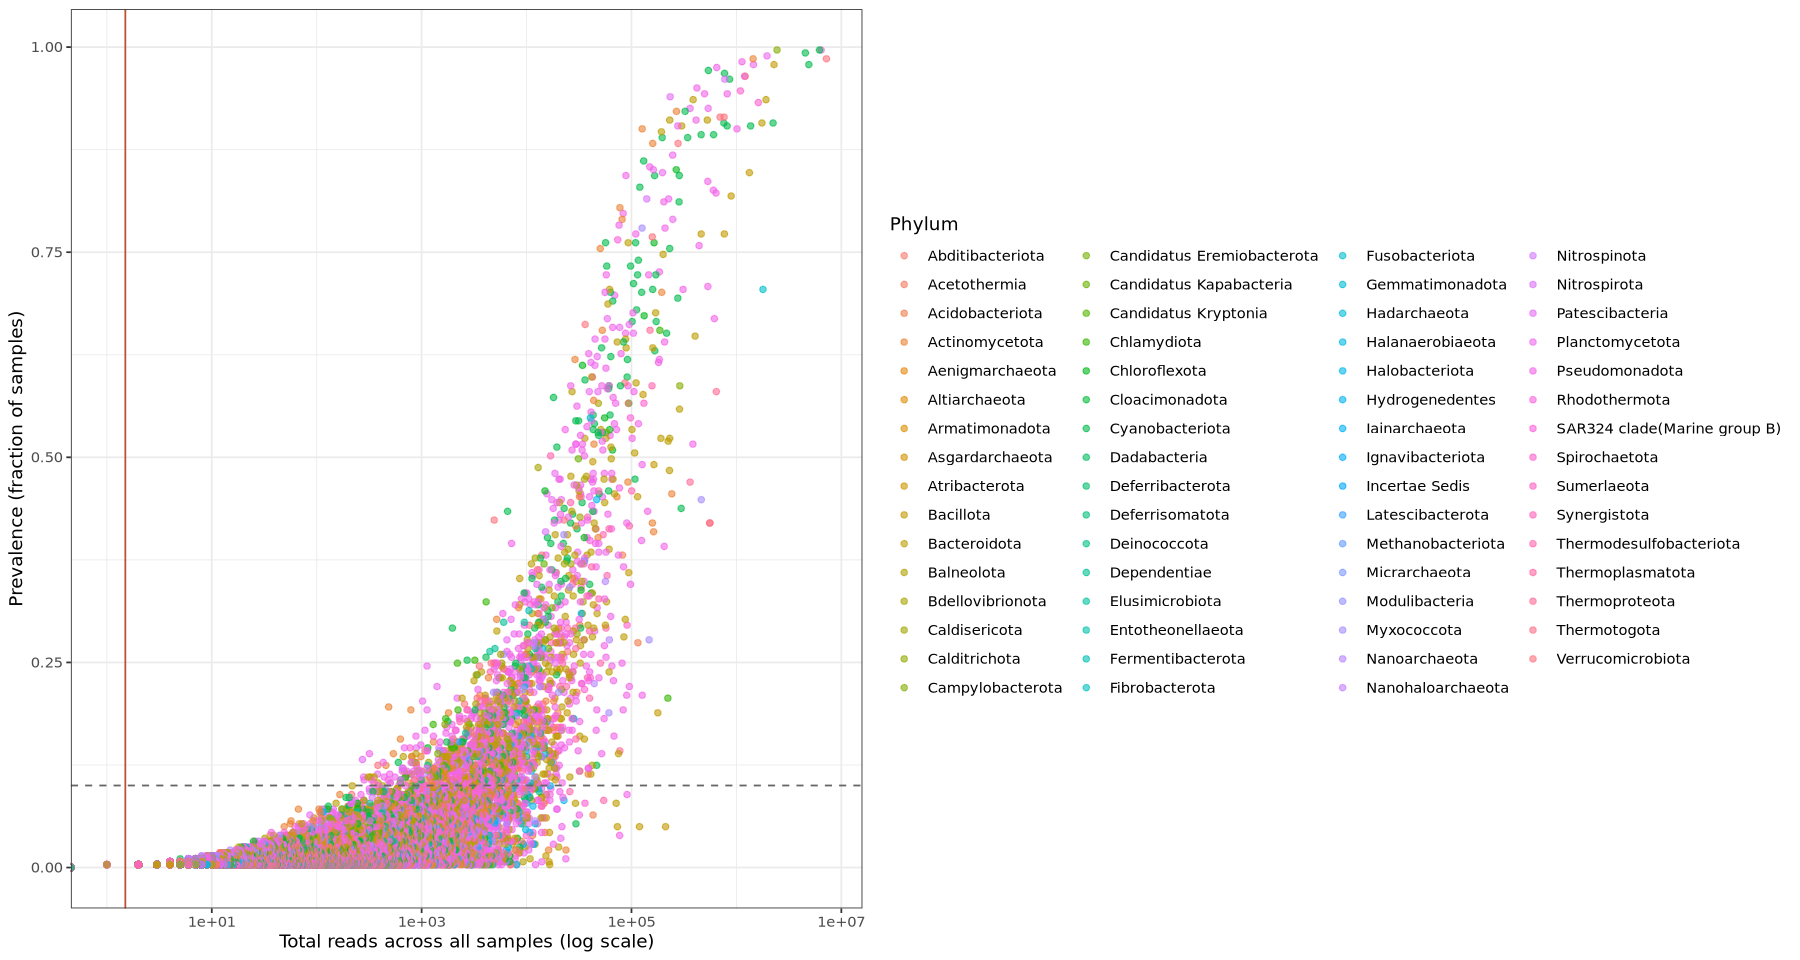

In [36]:
# Plot prevalence and mean abundance of ASVs
prev_df <- data.frame(
  ASV        = taxa_names(ps),
  Prevalence = microbiome::prevalence(ps, detection = 0, sort = FALSE, count = TRUE),
  TotalReads = taxa_sums(ps),
  Phylum     = as.character(tax_table(ps)[, "Phylum"])
) %>%
  mutate(
    PrevalenceFrac = Prevalence / nsamples(ps)
  )

ggplot(prev_df, aes(x = TotalReads, y = PrevalenceFrac, colour = Phylum)) +
  geom_point(alpha = 0.6) +
  scale_x_log10() +
  geom_vline(xintercept = 1.5, linetype = "solid",
             colour = "#bf4f2f") +
  geom_hline(yintercept = 0.10, linetype = "dashed",
             colour = "grey40") +
  labs(
    x = "Total reads across all samples (log scale)",
    y = "Prevalence (fraction of samples)"
  ) +
  theme_bw()

"The solid vertical line marks the singleton threshold (taxa_sums > 1) that we apply below. The dashed horizontal line marks where a 10% prevalence filter would cut, for reference. Most ASVs sit at very low prevalence — that’s characteristic of 16S data: a long tail of rare detections." - [tutorial](https://corebio.info/metabarcodingecology-tutorial-2026/02_filtering_transformations.html)

In [41]:
# Remove singletons
n_before <- ntaxa(ps)
ps_filt <- prune_taxa(taxa_sums(ps) > 1, ps)
n_after <- ntaxa(ps_filt)
message(sprintf(
  "Singleton filter: %d -> %d ASVs (%.1f%% retained)",
  n_before, n_after, 100 * n_after / n_before
))

# How many reads did we lose?
reads_before <- sum(otu_table(ps))
reads_after  <- sum(otu_table(ps_filt))
message(sprintf(
  "Reads retained: %.6f%%",
  100 * reads_after / reads_before
))

Singleton filter: 120374 -> 119007 ASVs (98.9% retained)

Reads retained: 99.999992%



In [42]:
# Save phyloseq object
saveRDS(ps_filt, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-filt.rds")

### Abundance transformation

> The simplest transformation is relative abundance (also called “compositional” or “total-sum scaling”): divide each count by the sample’s total, so every sample sums to 1. This is the right transformation when the question is “what fraction of this community is taxon X”. It is the standard input for stacked bar plots, Bray-Curtis distances, and most visualization.
>
> Relative abundance is not the right transformation for every question. In particular, it does not address the compositional nature of the data: because the values must sum to 1, an apparent increase in one taxon could be caused by a real increase in that taxon, a real decrease in another, or both. The CLR (centered log-ratio) transformation addresses this. - [tutorial](https://corebio.info/metabarcodingecology-tutorial-2026/02_filtering_transformations.html)

`ps_rel` should be used for relative abundance and bray-curtis distances  
`ps_clr` can be explored as an alternative to relative abundance that pairs with standard methods (i.e. Euclidean distance, PCA, linear models, etc.)

In [43]:
# Transform ASV raw counts to relative abundance per sample
ps_rel <- microbiome::transform(ps_filt, "compositional")

# Sanity check: every sample should now sum to 1
sample_sums(ps_rel) %>% summary()

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      1       1       1       1       1       1 

In [45]:
# Transform ASV raw counts via centered log-ratio (CLR)
ps_clr <- microbiome::transform(ps_filt, "clr")

# Inspect: CLR values are real numbers, positive and negative, centered around zero per sample
clr_values <- microbiome::abundances(ps_clr)
summary(as.vector(clr_values))

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.12904 -0.04670 -0.02992  0.00000 -0.01940 14.46578 

In [48]:
# Save phyloseq objects
saveRDS(ps_rel, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel.rds")
saveRDS(ps_clr, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-clr.rds")

## 11.3.26 | ordinate the data

In [56]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(microbiome)
})
    
options(repr.plot.width=15, repr.plot.height=8)

In [58]:
# Read in relative abundance phyloseq object
ps_rel <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel.rds")

In [59]:
# Add label to negative and positive controls in the tissue column
sample_data(ps_rel)$Tissue[grepl("negative", sample_names(ps_rel))] <- "Negative_control"
sample_data(ps_rel)$Tissue[grepl("Positive", sample_names(ps_rel))] <- "Positive_control"

### All samples

In [ ]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps_rel, method = "bray")

In [61]:
# Ordinate using PCoA
ord_bray <- ordinate(ps_rel, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
ord_bray$values$Relative_eig[1:5] %>% round(3)

[1] 0.145 0.094 0.063 0.049 0.037

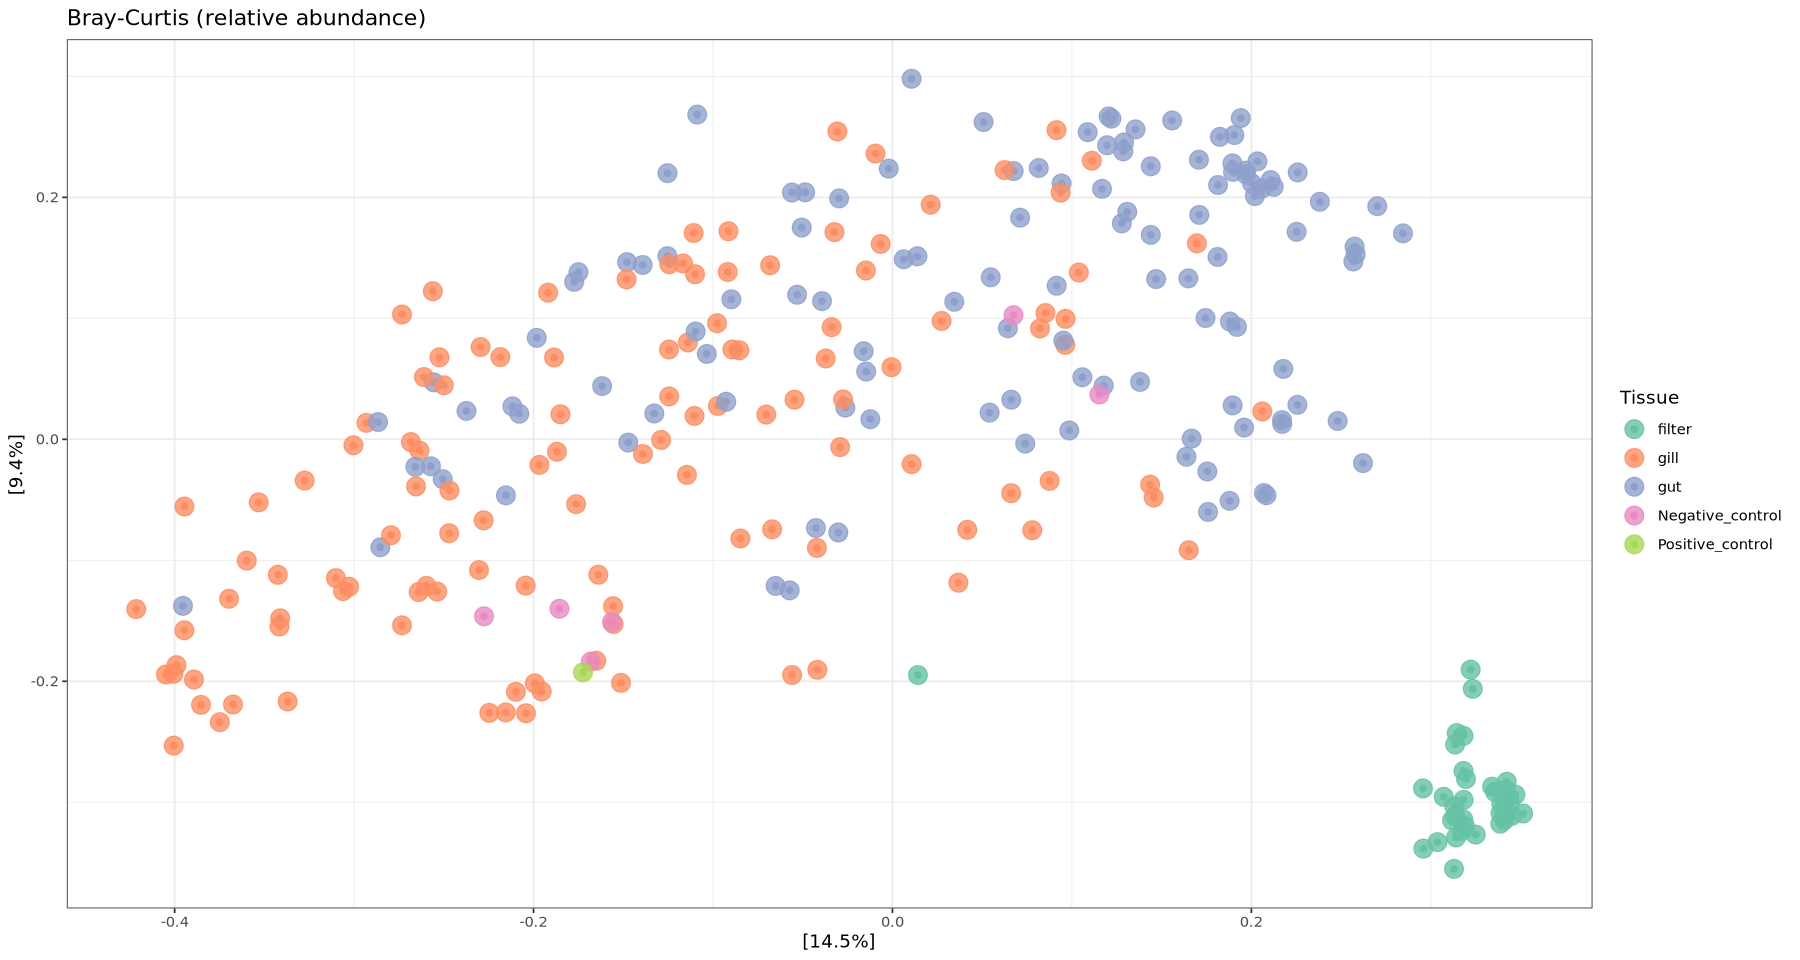

In [72]:
# Visualize PCoA
p_bray <- plot_ordination(ps_rel, ord_bray, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_bray

### All samples - only bacteria

In [74]:
# Keep only bacteria
ps_bacteria <- subset_taxa(ps_rel, Kingdom == "Bacteria")

# Remove taxa that were associated with the removed domains
ps_bacteria <- prune_taxa(taxa_sums(ps_bacteria) > 0, ps_bacteria)

# Compare phyloseq objects
ps_rel
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 119007 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 119007 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 119007 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 115643 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 115643 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 115643 reference sequences ]

In [75]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps_bacteria, method = "bray")

In [76]:
# Ordinate using PCoA
ord_bray <- ordinate(ps_bacteria, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
ord_bray$values$Relative_eig[1:5] %>% round(3)

[1] 0.149 0.092 0.062 0.049 0.038

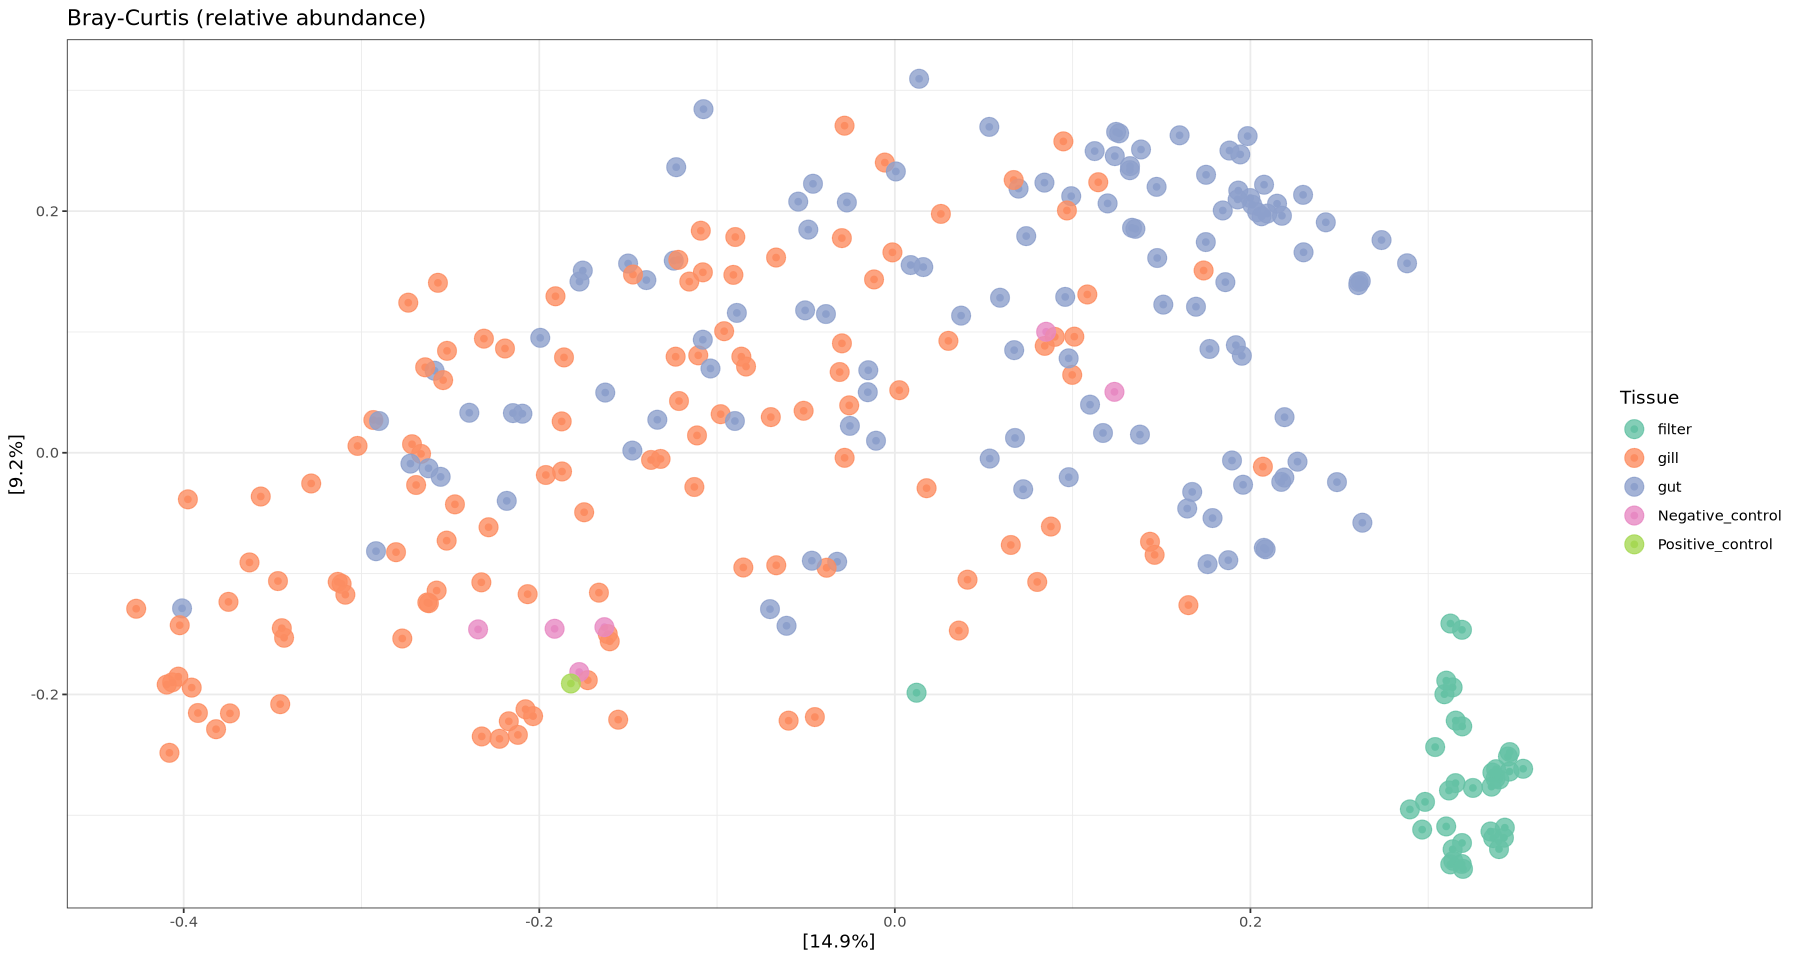

In [77]:
# Visualize PCoA
p_bray_bacteria <- plot_ordination(ps_bacteria, ord_bray, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_bray_bacteria

- Filter samples cluster tightly together and separate from tissue samples
- Large overlap between gill and gut tissue samples
- Negative controls overlap with gill and gut tissue samples; likely contamination

### Phase 1 - only bacteria

In [81]:
ps_p1 <- subset_samples(ps_bacteria, Phase == 1 | Tissue %in% c("Negative_control", "Positive_control"))
ps_p1 <- prune_taxa(taxa_sums(ps_p1) > 0, ps_p1)
ps_p1

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 38946 taxa and 67 samples ]
sample_data() Sample Data:       [ 67 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 38946 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 38946 reference sequences ]

### Phase 2 - only bacteria

In [80]:
ps_p2 <- subset_samples(ps_bacteria, Phase == 2 | Tissue %in% c("Negative_control", "Positive_control"))
ps_p2 <- prune_taxa(taxa_sums(ps_p2) > 0, ps_p2)
ps_p2

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 83804 taxa and 221 samples ]
sample_data() Sample Data:       [ 221 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 83804 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 83804 reference sequences ]